# Bell pairs on the three Fall Fest processor layouts

Prepare $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$ on each processor's red-circled ports. Compare ideal and noisy Bell fidelity using the three layouts on slide 4 of *Geometry-aware quantum cloud challenge* (quanTA, University of Saskatchewan).

Open in Jupyter and run the cells in order. If you need the dependencies, run `%pip install "qiskit>=2.1,<3" "qiskit-aer>=0.17" matplotlib` in a notebook cell first.

In [1]:
%matplotlib inline

from math import isclose

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, Statevector, partial_trace
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

## 1. Define the coupling graphs

The prompt diagrams have no qubit numbers, so the IDs below are assigned by position. The red circles in the prompt determine the port pairs. Each drawn link allows CX in both directions, and all three schematics use the same `h` and `cx` gate set here.

In [2]:
models = {
    "2016-inspired reference": {
        "ports": (0, 4),
        "positions": [(0, 2), (-1.55, 0.75), (1.55, 0.75), (0, -0.45), (0, -2)],
        "edges": [(0, 1), (0, 2), (0, 3), (3, 4)],
        "color": "#2151c7",
    },
    "Contemporary IBM-style": {
        "ports": (0, 7),
        "positions": [
            (-2.1, 1), (-0.9, 1.7), (0.3, 1), (1.5, 1.7),
            (-1.5, -0.35), (-0.3, 0.35), (0.9, -0.35), (2.1, 0.35), (-0.3, -1.65),
        ],
        "edges": [
            (0, 1), (0, 4), (1, 2), (1, 5), (2, 3), (2, 5), (2, 6),
            (3, 7), (4, 5), (5, 6), (5, 8), (6, 7),
        ],
        "color": "#137665",
    },
    "Hyperbolic-inspired model": {
        "ports": (0, 12),
        "positions": [
            (0, 2.08), (-2, 1.14), (0, 1.14), (2, 1.14),
            (-1, 0.59), (1, 0.59), (0, 0), (-1, -0.59), (1, -0.59),
            (-2, -1.14), (0, -1.14), (2, -1.14), (0, -2.08),
        ],
        "edges": [
            # Outer ring
            (0, 1), (0, 3), (1, 9), (3, 11), (9, 12), (11, 12),
            # Inner ring
            (2, 4), (2, 5), (4, 7), (5, 8), (7, 10), (8, 10),
            # Outer-to-inner links
            (0, 2), (1, 4), (3, 5), (7, 9), (8, 11), (10, 12),
            # Center-to-inner links
            (2, 6), (4, 6), (5, 6), (6, 7), (6, 8), (6, 10),
        ],
        "color": "#7139cc",
    },
}

## 2. Compile the Bell circuit

Start with an H on logical qubit 0 and a CX from 0 to 1. Place those logical qubits on the red ports. Qiskit's basic router inserts SWAPs until the CX can run between neighbors. Apply the same SWAPs in reverse order after the CX to bring the Bell pair back to the ports. A second transpile pass expands each SWAP into three CX gates with the physical wire order fixed. [Qiskit transpile documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/compiler)

In [3]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
print(bell.draw(output="text"))

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [4]:
def compile_at_ports(bell, edges, ports):
    coupling = CouplingMap(edges)
    coupling.make_symmetric()

    routed = transpile(
        bell,
        coupling_map=coupling,
        initial_layout=list(ports),
        routing_method="basic",
        basis_gates=["h", "cx", "swap"],
        optimization_level=0,
    )
    swaps = [
        tuple(routed.find_bit(q).index for q in instruction.qubits)
        for instruction in routed.data
        if instruction.operation.name == "swap"
    ]

    # Copy the instructions into a circuit indexed by physical wire.
    at_ports = QuantumCircuit(routed.num_qubits)
    at_ports.compose(routed, inplace=True)
    for a, b in reversed(swaps):
        at_ports.swap(a, b)

    compiled = transpile(
        at_ports,
        coupling_map=coupling,
        initial_layout=list(range(at_ports.num_qubits)),
        routing_method="none",
        basis_gates=["h", "cx"],
        optimization_level=0,
    )
    return compiled, len(swaps)


results = {}
for name, model in models.items():
    circuit, route_swaps = compile_at_ports(bell, model["edges"], model["ports"])
    used_edges = {
        tuple(sorted(circuit.find_bit(q).index for q in instruction.qubits))
        for instruction in circuit.data
        if len(instruction.qubits) == 2
    }
    assert used_edges <= set(model["edges"]), f"{name} has a gate off the coupling graph"
    results[name] = {"circuit": circuit, "route_swaps": route_swaps, "used_edges": used_edges}

## 3. Draw the graphs and compiled circuits

Red rings mark the output ports. Darker links carry CX gates in the compiled circuit. Circuit wire numbers match the graph labels, and idle wires are hidden.

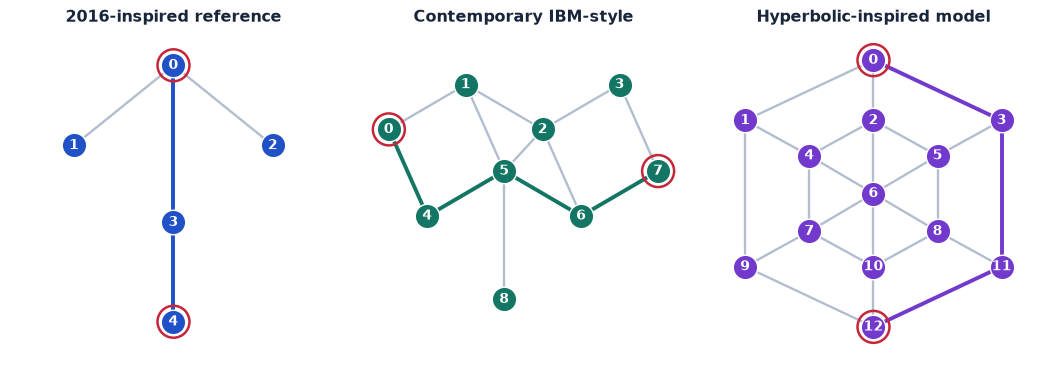

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.55), layout="constrained", facecolor="white")

for (name, model), ax in zip(models.items(), axes):
    positions = model["positions"]
    color = model["color"]
    for a, b in model["edges"]:
        x0, y0 = positions[a]
        x1, y1 = positions[b]
        used = (a, b) in results[name]["used_edges"]
        ax.plot([x0, x1], [y0, y1], color=color if used else "#b2becf",
                linewidth=2.8 if used else 1.7, zorder=1)

    ax.scatter(*zip(*positions), s=310, color=color, edgecolors="white", zorder=3)
    port_positions = [positions[q] for q in model["ports"]]
    ax.scatter(*zip(*port_positions), s=530, facecolors="none", edgecolors="#c62639",
               linewidths=1.8, zorder=2)
    for qubit, (x, y) in enumerate(positions):
        ax.text(x, y, str(qubit), ha="center", va="center",
                color="white", fontsize=10, weight="bold", zorder=4)

    ax.set_title(name, fontsize=11.5, weight="bold", color="#18253b")
    ax.set(xlim=(-2.55, 2.55), ylim=(-2.55, 2.55), aspect="equal")
    ax.axis("off")

plt.show()

In [6]:
for name, result in results.items():
    port_a, port_b = models[name]["ports"]
    display(Markdown(f"**{name} · ports {port_a} and {port_b}**"))
    print(result["circuit"].draw(output="text", idle_wires=False, with_layout=False, fold=-1))

**2016-inspired reference · ports 0 and 4**

     ┌───┐     ┌───┐               ┌───┐     
q_0: ┤ H ├──■──┤ X ├──■─────────■──┤ X ├──■──
     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐
q_3: ─────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├
          └───┘     └───┘┌─┴─┐└───┘     └───┘
q_4: ────────────────────┤ X ├───────────────
                         └───┘               


**Contemporary IBM-style · ports 0 and 7**

     ┌───┐     ┌───┐                                                                           ┌───┐     
q_0: ┤ H ├──■──┤ X ├──■─────────────────────────────────────────────────────────────────────■──┤ X ├──■──
     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐                                             ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐
q_4: ─────┤ X ├──■──┤ X ├──■──┤ X ├──■───────────────────────────────────────■──┤ X ├──■──┤ X ├──■──┤ X ├
          └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐               ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘
q_5: ────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■─────────■──┤ X ├──■──┤ X ├──■──┤ X ├───────────────
                         └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘               
q_6: ───────────────────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├──────────────────────────────
                                        └───┘     └───┘┌─┴─┐└───┘     └───┘                              
q_7: ─────────────────────────────────────────

**Hyperbolic-inspired model · ports 0 and 12**

      ┌───┐     ┌───┐                                             ┌───┐     
 q_0: ┤ H ├──■──┤ X ├──■───────────────────────────────────────■──┤ X ├──■──
      └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐               ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐
 q_3: ─────┤ X ├──■──┤ X ├──■──┤ X ├──■─────────■──┤ X ├──■──┤ X ├──■──┤ X ├
           └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘
q_11: ────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├───────────────
                          └───┘     └───┘┌─┴─┐└───┘     └───┘               
q_12: ───────────────────────────────────┤ X ├──────────────────────────────
                                         └───┘                              


## 4. Compare ideal and noisy fidelity at the red ports

Run the same compiled circuits in both cases. The noisy run applies a two-qubit depolarizing channel after each CX, including the CX gates that implement SWAPs. All layouts use the same strength, set below to $0.02$, which mixes the affected pair 2% toward the maximally mixed state. H gates are ideal in this synthetic model. [Qiskit Aer depolarizing channel](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html)

Both runs start from the all-zero state and use the reduced state of the two physical ports. Aer evolves a density matrix for the noisy run, so the Pauli correlations are computed directly without sampling measurement outcomes.

$$F_{\Phi^+} = \frac{1+\langle XX\rangle-\langle YY\rangle+\langle ZZ\rangle}{4}$$

The SWAP column counts outbound and return SWAPs before expansion. The CX count and depth come from the final circuit.

In [7]:
cx_depolarizing_strength = 0.02
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(cx_depolarizing_strength, 2), ["cx"]
)
noisy_simulator = AerSimulator(method="density_matrix", noise_model=noise_model)

In [8]:
def bell_metrics(port_state):
    xx, yy, zz = (
        port_state.expectation_value(Pauli(basis)).real for basis in ("XX", "YY", "ZZ")
    )
    fidelity = (1 + xx - yy + zz) / 4
    return (xx, yy, zz), fidelity


table = [
    "| Model | Ports | SWAPs out + back | CX | Depth | Ideal XX / YY / ZZ | Ideal fidelity | Noisy fidelity |",
    "|:--|:--:|--:|--:|--:|:--:|--:|--:|",
]
for name, result in results.items():
    circuit = result["circuit"]
    ports = models[name]["ports"]

    ideal_state = Statevector.from_instruction(circuit)
    other_wires = [q for q in range(circuit.num_qubits) if q not in ports]
    ideal_ports = partial_trace(ideal_state, other_wires)
    (xx, yy, zz), ideal_fidelity = bell_metrics(ideal_ports)
    assert isclose(ideal_fidelity, 1.0, rel_tol=0, abs_tol=1e-9), (
        f"{name}: expected unit fidelity on ports {ports}, got {ideal_fidelity}"
    )

    noisy_circuit = circuit.copy()
    noisy_circuit.save_density_matrix(list(ports), label="ports")
    noisy_result = noisy_simulator.run(noisy_circuit, shots=1).result()
    _, noisy_fidelity = bell_metrics(noisy_result.data(0)["ports"])

    swaps = result["route_swaps"]
    correlations = f"{xx:+.0f} / {yy:+.0f} / {zz:+.0f}"
    table.append(
        f"| {name} | {ports[0]}, {ports[1]} | {swaps} + {swaps} | "
        f"{circuit.count_ops()['cx']} | {circuit.depth()} | {correlations} | "
        f"{ideal_fidelity:.3f} | {noisy_fidelity:.3f} |"
    )

display(Markdown("\n".join(table)))

| Model | Ports | SWAPs out + back | CX | Depth | Ideal XX / YY / ZZ | Ideal fidelity | Noisy fidelity |
|:--|:--:|--:|--:|--:|:--:|--:|--:|
| 2016-inspired reference | 0, 4 | 1 + 1 | 7 | 8 | +1 / -1 / +1 | 1.000 | 0.915 |
| Contemporary IBM-style | 0, 7 | 3 + 3 | 19 | 20 | +1 / -1 / +1 | 1.000 | 0.795 |
| Hyperbolic-inspired model | 0, 12 | 2 + 2 | 13 | 14 | +1 / -1 / +1 | 1.000 | 0.852 |